## 1 - Dados históricos de partidas de futebol entre seleções.

Como o futebol entre seleções evoluiu ao longo de quase 150 anos e quais padrões estatísticos podem ser encontrados nesse período?

Ao todo, segundo o site da FIFA, até a data de 22/07/2026, existem 45.831 partidas de futebol oficias realizadas. Essas partidas ocorreram em diferentes épocas, passando por significativas evoluções nas regras, estruturas e táticas. Ao longo desses anos, diferentes competições foram sendo criadas, e algumas, embora tenham sofrido diversas alterações no formato, permanecem em disputa ainda nos dias de hoje.

Para a análise, as seguintes bibliotecas serão importadas:

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import ticker
import numpy as np
from enum import StrEnum, Enum
from math import sqrt
import warnings
from scipy.stats import norm, shapiro, mannwhitneyu, chi2_contingency
warnings.filterwarnings("ignore")

## 2 - Conhecendo os dados

Os dados foram obtidos através das API da FIFA que são utilizadas na página [International match archive](https://inside.fifa.com/data-centre/matches/men).

Foi criado um [script](https://github.com/AdaLimana/pos-ia/blob/main/projeto-02/index.js) para a coleta dos dados e o resultado foi salvo em um [arquivo](https://github.com/AdaLimana/pos-ia/blob/main/projeto-02/2026-07-22T22%3A38%3A38.478Z-fifa-data.json) json.

In [40]:
BASE_URL = "https://raw.githubusercontent.com/AdaLimana/pos-ia/refs/heads/main/projeto-02/"

df_partidas = pd.read_json(BASE_URL + "2026-07-22T22:38:38.478Z-fifa-data.json")
# df_partidas = df_partidas.replace(r'^\s*$', np.nan, regex=True)
print("Dados carregados com sucesso!")
print(f"Partidas: {df_partidas.shape[0]} registros")

Dados carregados com sucesso!
Partidas: 45831 registros


### 2.1 - Dicionário de dados

Antes de analisar, devemos entender o significado das colunas. Isso reduz erros de interpretação e ajuda decidir quais estratégias podem ser utilizadas quando for limpar e normalizar os dados.

In [41]:
df_dicionario = pd.read_csv(BASE_URL + "dictionary.csv")
df_dicionario = df_dicionario.fillna("")
df_dicionario

,Coluna,Tipo,Descrição,Observação
0,idMatch,chave,Identificador único de uma partida,Útil caso queira cruzar com outros dados da FI...
1,idMatchIfes,chave,Identificador interno da FIFA,
2,idCompetition,chave,Identificador da competição que partida foi re...,Útil caso queria agrupar informações por compe...
3,competitionName,categórico,Nome da competição que partida foi realizada. ...,Fornece um contexto legível sobre a competição
4,idSeason,chave,Identificador da competição na data que partid...,Útil caso queria agrupar informações por compe...
5,seasonName,categórico,Nome da competição na data que partida foi rea...,Fornece um contexto legível sobre a competição...
6,idStage,chave,Identificador da fase da competição que partid...,Útil caso queria agrupar informações por fases...
7,stageName,categórico,Nome da fase da competição que partida foi rea...,Fornece um contexto legível sobre a fase
8,matchDate,datetime,Data que a partida foi realizada,Útil para separar e agrupar intervalos
9,teamAId,chave,Identificador único de uma seleção,Pode se utilizado para identificar o vencedor ...


###2.2 - Limpeza e normalização dos dados

Antes de qualquer análise, é fundamental inspecionar a estrutura, tipos, valores ausentes e possíveis inconsistências nos dados. Esse passo orienta decisões de tratamento e evita interpretações equivocadas.

In [42]:
print("TIPOS DOS DADOS")
df_partidas.info()
print()

print("VALORES AUSENTES")
nulos = df_partidas.isnull().sum()
colunas_com_nulos = nulos[nulos > 0]
colunas_com_nulos
total = df_partidas.shape[0]

if len(colunas_com_nulos):
  for col, qtd in colunas_com_nulos.items():
    print(f"[Partidas] '{col}': {qtd} nulos ({qtd/total:.1%})")
else:
  print(f"[Partidas]: sem valores ausentes")

print()

print("DUPLICATAS")
dup = df_partidas.duplicated().sum()
status = f"{dup} duplicatas" if dup > 0 else "Sem duplicatas"
print(f"[Partidas]: {status}")

TIPOS DOS DADOS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45831 entries, 0 to 45830
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   idMatch            45831 non-null  object
 1   idMatchIfes        45831 non-null  int64 
 2   idCompetition      45831 non-null  object
 3   idSeason           45831 non-null  object
 4   idStage            45831 non-null  object
 5   competitionName    45831 non-null  object
 6   seasonName         45831 non-null  object
 7   matchDate          45831 non-null  object
 8   teamAId            45831 non-null  int64 
 9   teamBId            45831 non-null  int64 
 10  teamAName          45831 non-null  object
 11  teamBName          45831 non-null  object
 12  teamACountryCode   45831 non-null  object
 13  teamBCountryCode   45831 non-null  object
 14  teamAScore         45831 non-null  int64 
 15  teamBScore         45831 non-null  int64 
 16  teamAPenaltyScore  45831

####2.2.1 Alteração tipos de dados

In [43]:
print("Coluna `matchDate` antes dos cast para datetime")
display(df_partidas['matchDate'])
print()

df_partidas['matchDate'] = pd.to_datetime(df_partidas['matchDate'])

print("Coluna `matchDate` depois dos cast para datetime")
display(df_partidas['matchDate'])

Coluna `matchDate` antes dos cast para datetime


,matchDate
0,1872-11-30
1,1873-03-08
2,1874-03-07
3,1875-03-06
4,1876-03-04
...,...
45826,2026-07-12
45827,2026-07-14
45828,2026-07-15
45829,2026-07-18



Coluna `matchDate` depois dos cast para datetime


,matchDate
0,1872-11-30
1,1873-03-08
2,1874-03-07
3,1875-03-06
4,1876-03-04
...,...
45826,2026-07-12
45827,2026-07-14
45828,2026-07-15
45829,2026-07-18


####2.2.2 Coluna `stadiumName`

A coluna `stadiumName`será removida, pois não é relevante para a análise.

In [44]:
df_partidas.drop('stadiumName', axis=1, inplace=True)

####2.2.3 Coluna `stageName`

A coluna `stageName`será removida, pois não é relevante para a análise.

In [45]:
df_partidas.drop('stageName', axis=1, inplace=True)

####2.2.4 Coluna `competitionName`

Os valores da coluna serão divididos em 6 categorias:

- **Amistoso**:	Friendly
- **Campeonato Amistoso**: FIFA Series, e demais torneios promocionais que foram disputados durante os anos.
- **Eliminatórias**:	Todas as qualificatórias
- **Competições Continentais**: Continental Final, Nations League
- **Copa do Mundo**: FIFA World Cup
- **Competições Mundiais**: FIFA Confederations Cup, FIFA Arab Cup, Olympic Football Tournament Final


In [46]:
class CampeonatosEnum(StrEnum):
    AMISTOSO = "Amistoso"
    COMPETICOES_AMISTOSAS = "Competicoes Amistosas"
    ELIMINATORIAS = "Eliminatórias"
    COMPETICOES_CONTINENTAIS = "Competições Continentais"
    COPA_DO_MUNDO = "Copa do Mundo"
    OUTRAS_COMPETICOES_INTERNACIONAIS = "Outras Competições Internacionais"

campeonatos = set(df_partidas["competitionName"])

print(f"#Existem ao todo {len(campeonatos)} campeonatos\n")

for campeonato in campeonatos:
  print(f"- {campeonato}")

print("\n#Normalizando as competições das partidas para 6 categorias\n")

dados = [
  {
    "competicao": CampeonatosEnum.AMISTOSO.value,
    "filtros": (df_partidas["competitionName"].str.strip().isin(["Friendly", "FIFA Competitions™"])) & (df_partidas["seasonName"].str.startswith("Friendly"))
  },
  {
    "competicao": CampeonatosEnum.AMISTOSO.COMPETICOES_AMISTOSAS.value,
    "filtros": (df_partidas["competitionName"] == "FIFA Series™") | ((df_partidas["competitionName"] == "Friendly") & (~df_partidas["seasonName"].str.startswith("Friendly")))
  },
  {
    "competicao": CampeonatosEnum.ELIMINATORIAS.value,
    "filtros": df_partidas["competitionName"].str.strip().isin(["Continental Qualifier", "FIFA Arab Cup™ Qualification", "FIFA World Cup™ Qualifiers"])
  },
  {
    "competicao": CampeonatosEnum.COMPETICOES_CONTINENTAIS.value,
    "filtros": df_partidas["competitionName"].str.strip().isin(["Continental Final", "Nations League"])
  },
  {
    "competicao": CampeonatosEnum.COPA_DO_MUNDO.value,
    "filtros": df_partidas["competitionName"].str.strip() == "FIFA World Cup™"
  },
  {
    "competicao": CampeonatosEnum.OUTRAS_COMPETICOES_INTERNACIONAIS.value,
    "filtros": df_partidas["competitionName"].str.strip().isin(["Olympic Football Tournament™ Final", "FIFA Confederations Cup™", "FIFA Arab Cup™"])
  },
]

for item in dados:
  df_partidas.loc[item["filtros"], 'competitionName'] = item["competicao"]
  total = len(df_partidas[df_partidas["competitionName"] == item["competicao"]])
  print(f"#Total de registros normalizados para a categoria {item["competicao"]}: {total}")

campeonatos = set(df_partidas["competitionName"])

print(f"\n#Após a normalização, existem ao todo {len(campeonatos)} campeonatos\n")

for campeonato in campeonatos:
  print(f"- {campeonato}")



#Existem ao todo 12 campeonatos

- FIFA World Cup™ Qualifiers
- Continental Qualifier
- FIFA Confederations Cup™
- Continental Final
- FIFA World Cup™
- FIFA Competitions™
- FIFA Arab Cup™ Qualification
- FIFA Arab Cup™ 
- Nations League
- Friendly
- Olympic Football Tournament™ Final
- FIFA Series™

#Normalizando as competições das partidas para 6 categorias

#Total de registros normalizados para a categoria Amistoso: 15391
#Total de registros normalizados para a categoria Competicoes Amistosas: 8936
#Total de registros normalizados para a categoria Eliminatórias: 16051
#Total de registros normalizados para a categoria Competições Continentais: 4055
#Total de registros normalizados para a categoria Copa do Mundo: 1068
#Total de registros normalizados para a categoria Outras Competições Internacionais: 330

#Após a normalização, existem ao todo 6 campeonatos

- Competições Continentais
- Eliminatórias
- Copa do Mundo
- Outras Competições Internacionais
- Amistoso
- Competicoes Amistosa

####2.2.4 Coluna `totalGols`

A coluna `totalGols` será criada para ter o total de gols de uma partida, o valor será obtido através da soma dos gols marcados por ambas as equipes.

In [47]:
df_partidas['totalGols'] = df_partidas['teamAScore'] + df_partidas['teamBScore']

In [48]:
df_partidas.groupby('totalGols').agg(contagem=('totalGols', 'count')).sort_values(by="contagem", ascending=False).reset_index()

,totalGols,contagem
0,2,10437
1,3,9100
2,1,8142
3,4,6354
4,0,3831
5,5,3780
6,6,2001
7,7,1077
8,8,526
9,9,273


### 2.3 - Panorama geral dos dados
O conjunto de dados é composto por mais de 45 mil partidas internacionais disputadas entre 1872 e 19/07/2026, envolvendo 242 seleções nacionais e diferentes tipos de competições oficiais e amistosas.

In [49]:
print(f"Total de partidas: {len(df_partidas)}")
print(f"Período: {df_partidas['matchDate'].min().strftime('%Y')} - {df_partidas['matchDate'].max().strftime('%d/%m/%Y')}")

selecoes = set(pd.concat([df_partidas['teamAName'],df_partidas['teamBName']]))
print(f"Seleções: {len(selecoes)}")

competicoes = set(df_partidas['competitionName'])
print(f"Competições: {len(competicoes)}")

Total de partidas: 45831
Período: 1872 - 19/07/2026
Seleções: 242
Competições: 6


##3 - Como é uma partida típica?

### 3.1 - Quantos gols normalmente acontecem em uma partida?

Número de gols marcados
Total: 130428
Média: 2.85
Mediana: 3.00
Desvio padrão: 1.98



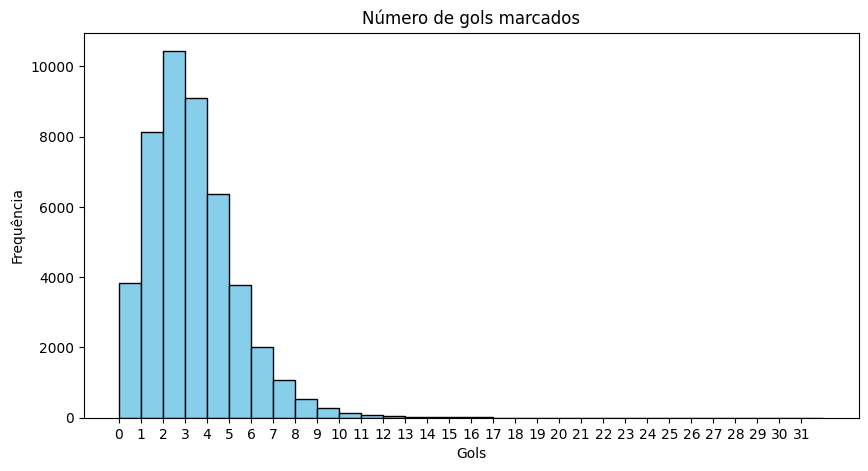

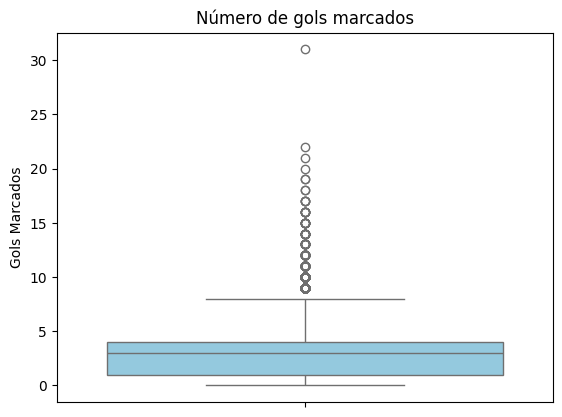

In [50]:
total_gols = df_partidas['totalGols'].sum()
print("Número de gols marcados")
print(f"Total: {total_gols}")
print(f"Média: {df_partidas['totalGols'].mean():.2f}")
print(f"Mediana: {df_partidas['totalGols'].median():.2f}")
print(f"Desvio padrão: {df_partidas['totalGols'].std():.2f}")


print()

plt.figure(figsize=(10,5))
plt.hist(
  df_partidas['totalGols'],
  bins=range(df_partidas['totalGols'].max()+2),
  color='skyblue',
  edgecolor='black',
)

plt.xticks(range(df_partidas["totalGols"].max() + 1))
plt.title('Número de gols marcados')
plt.xlabel('Gols')
plt.ylabel('Frequência')
plt.show()
print()

sns.boxplot(df_partidas['totalGols'], color='skyblue')
plt.title('Número de gols marcados')
plt.xlabel('')
plt.ylabel('Gols Marcados')

plt.show()

Foram analisados **130.428 gols** marcados em partidas oficiais entre seleções, resultando em uma **média de 2,85 gols por partida** e **mediana de 3 gols.** A proximidade entre essas medidas indica que a distribuição é relativamente concentrada em torno de três gols por jogo. O histograma mostra que a maior parte das partidas apresenta entre **1 e 4 gols**, com pico de frequência em **2 e 3 gols**.

A distribuição apresenta **assimetria positiva (cauda à direita)**, caracterizada pela redução gradual da frequência à medida que aumenta o número de gols. O **desvio padrão de 1,98 gols** indica uma dispersão moderada em torno da média, sugerindo que, na maioria dos jogos, o número de gols não se afasta significativamente desse valor. O boxplot confirma a presença de diversos **outliers superiores**, correspondentes a partidas com nove ou mais gols, que, embora raras, representam resultados reais e contribuem para o alongamento da cauda da distribuição.

### 3.2 - Como normalmente terminam os jogos?

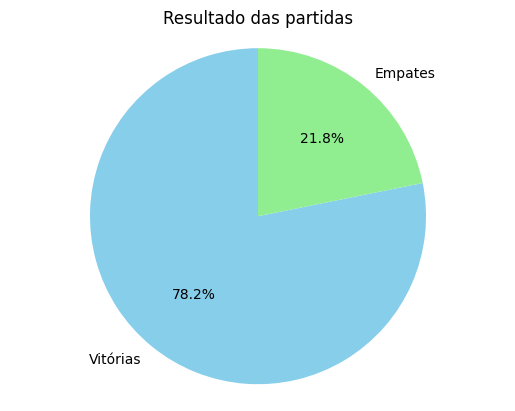

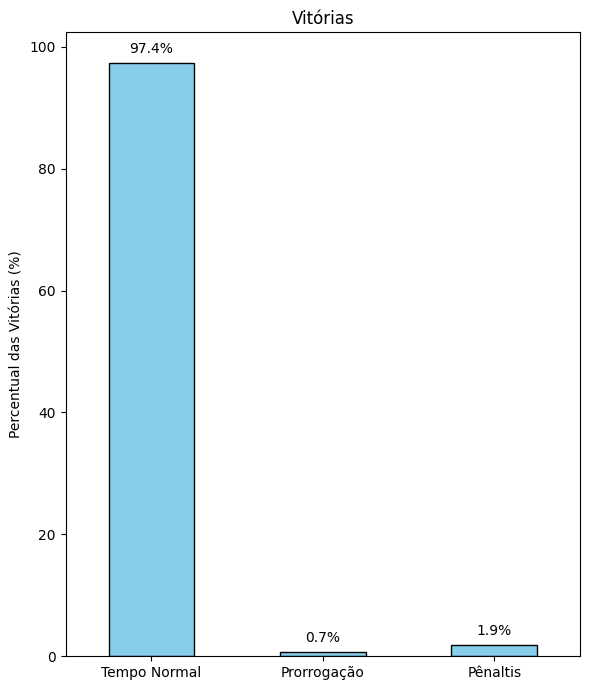

In [51]:
class ResultadoEnum(Enum):
    DECIDIDO_TEMPO_NORMAL = 1
    DECIDIDO_PENALIDADES = 2
    DECIDIDO_PRORROGACAO = 3

class LabelsResultadosEnum(StrEnum):
    DECIDIDO_TEMPO_NORMAL = "Decidido no Tempo Normal"
    DECIDIDO_PENALIDADES = "Decidido nos Pênaltis"
    DECIDIDO_PRORROGACAO = "Decidico na Prorrogação"

e_empate = df_partidas['winner'].isna() | (df_partidas['winner'].str.strip() == '')
contagem_resultados = e_empate.value_counts().rename({True: 'Empates', False: 'Vitórias'})

pct_resultados = (contagem_resultados / len(df_partidas)) * 100

pct_resultados.plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=['skyblue', 'lightgreen'],
    ylabel=''
)

plt.title('Resultado das partidas')
plt.axis('equal')
plt.show()

print()

df_vitorias = df_partidas[~e_empate]
contagem_vitorias = contagem_vitorias = df_vitorias['resultType'].value_counts()
vitorias_mapeadas = pd.Series({
    "Tempo Normal": contagem_vitorias.get(ResultadoEnum.DECIDIDO_TEMPO_NORMAL.value, 0),
    "Prorrogação": contagem_vitorias.get(ResultadoEnum.DECIDIDO_PRORROGACAO.value, 0),
    "Pênaltis": contagem_vitorias.get(ResultadoEnum.DECIDIDO_PENALIDADES.value, 0),
})

pct_vitorias = (vitorias_mapeadas / len(df_vitorias)) * 100

fig, ax = plt.subplots(figsize=(6, 7))

pct_vitorias.plot(kind='bar', color='skyblue', edgecolor='black', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=5)
plt.title('Vitórias')
plt.ylabel('Percentual das Vitórias (%)')
plt.xticks(rotation=0)
plt.ylim(0, pct_vitorias.max() + 5)
plt.tight_layout()
plt.show()

Conforme apresentado no gráfico de resultados, **78,2% das pertidas terminam com vitória de uma das seleções**, enquanto **21,8% terminam empatadas**. Isso indica que, embora os empates sejam relativamente frequentes, aproximadamente quatro em cada cinco jogos têm um vencedor ao final da partida.

Entre as partidas que terminam com vitória, **97,4% são decididas no tempo regulamentar**, enquanto apenas **1,9% são definidas nos pênaltis** e **0,7% na prorrogação**. Esses resultados demonstram que desfechos que exigem tempo extra são pouco frequentes, uma vez que ocorrem apenas em competições e fases eliminatórias específicas. Assim, é possível concluir que o resultado mais comum das partidas entre seleções é uma vitória durante o tempo normal de jogo.

## 4 - O futebol mudou ao longo da história?


### 4.1 - Partidas ao longo dos anos

Como evoluiu a quantidade de partidas internacionais ao longo dos anos?

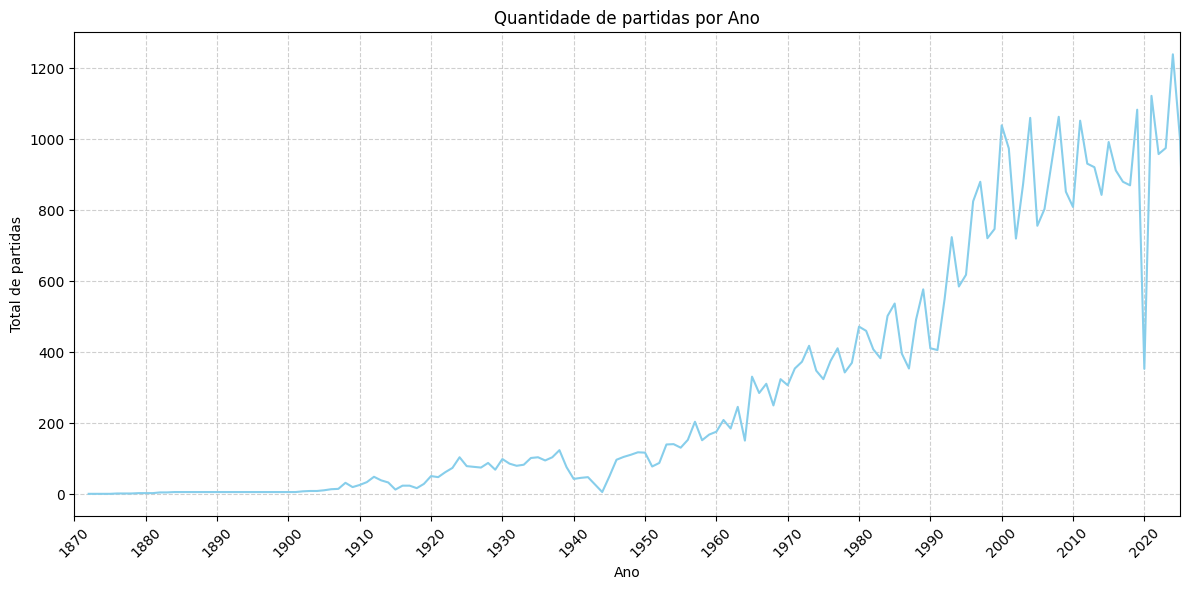

In [52]:
partidas_por_ano = df_partidas['matchDate'].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 6))
partidas_por_ano.plot(kind='line', color='skyblue', linewidth=1.5, ax=ax)

ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_xlim(1870, 2025)
plt.xticks(rotation=45)

plt.title('Quantidade de partidas por Ano')
plt.xlabel('Ano')
plt.ylabel('Total de partidas')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

O gráfico evidencia uma tendência de crescimento contínuo no número de partidas oficiais entre seleções ao longo dos anos. Nas primeiras décadas, a quantidade de jogos era reduzida, aumentando gradualmente com a expansão do futebol internacional. É possível observar também quedas acentuadas durante a Segunda Guerra Mundial e em 2020, decorrente da pandemia de COVID-19.

A partir da década de 1990, é possível observar um crescimento mais acelerado, acompanhado de oscilações periódicas. Essas variações refletem, em parte, a alternância do calendário internacional, com redução no número de partidas em anos de Copa do Mundo FIFA, quando parte das datas é destinada à realização do torneio, e aumento nos anos de disputas das eliminatórias. Após a queda observada em 2020, o número de partidas volta a crescer, atingindo os maiores valores da série histórica nos anos mais recentes.


### 4.2 - Média de gols por década

Como evoluiu a média de gols ao longo dos anos?

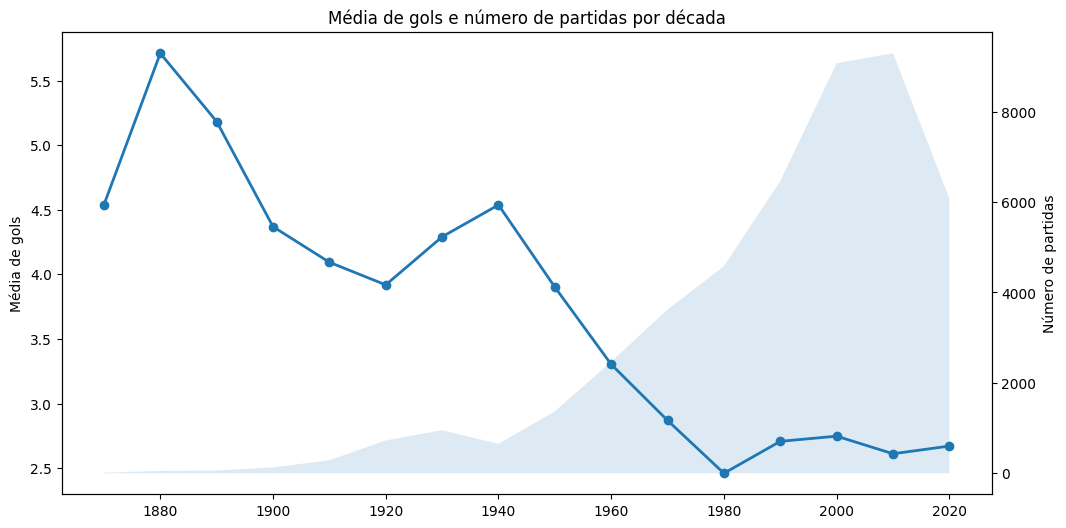

In [53]:
dados = (df_partidas.groupby((df_partidas['matchDate'].dt.year//10)*10).agg(
    media_gols=("totalGols", "mean"),
    partidas=("totalGols", "size")
).reset_index())

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    dados["matchDate"],
    dados["media_gols"],
    marker="o",
    linewidth=2,
    label="Média de gols"
)

ax1.set_ylabel("Média de gols")

ax2 = ax1.twinx()

ax2.fill_between(
    dados["matchDate"],
    dados["partidas"],
    alpha=0.15
)

ax2.set_ylabel("Número de partidas")

plt.title("Média de gols e número de partidas por década")

plt.show()

O gráfico apresenta a evolução da média de gols por partida e da quantidade de partidas disputadas por década. É possível observar que, nas primeiras décadas, a média de gols era mais elevada, variando entre aproximadamente 4 e 6 gols por partida, porém esse período também é caracterizado por um número reduzido de partidas. Dessa forma, pequenas variações nos resultados tinham grande impacto sobre a média, tornando ela mais suscetível a oscilações.

A partir da segunda metade do seculo XX, é possível verificar um crescimento expressivo na quantidade de partidas, refletindo a expansão do futebol internacional e do calendário de competições. Paralelamente, a média de gols apresenta uma tendência de redução, estabilizando em torno de 2,6 a 2,8 gols por partida desde a década de 1980. Esse comportamento sugere que, apesar do aumento significativo no número de jogos, o padrão de gols se tornou mais consistente ao longo do tempo, indicando maior equilíbrio entre as seleções e maior representatividade das médias calculadas nas décadas mais recentes.

### 4.3 - Percentual de empates por década

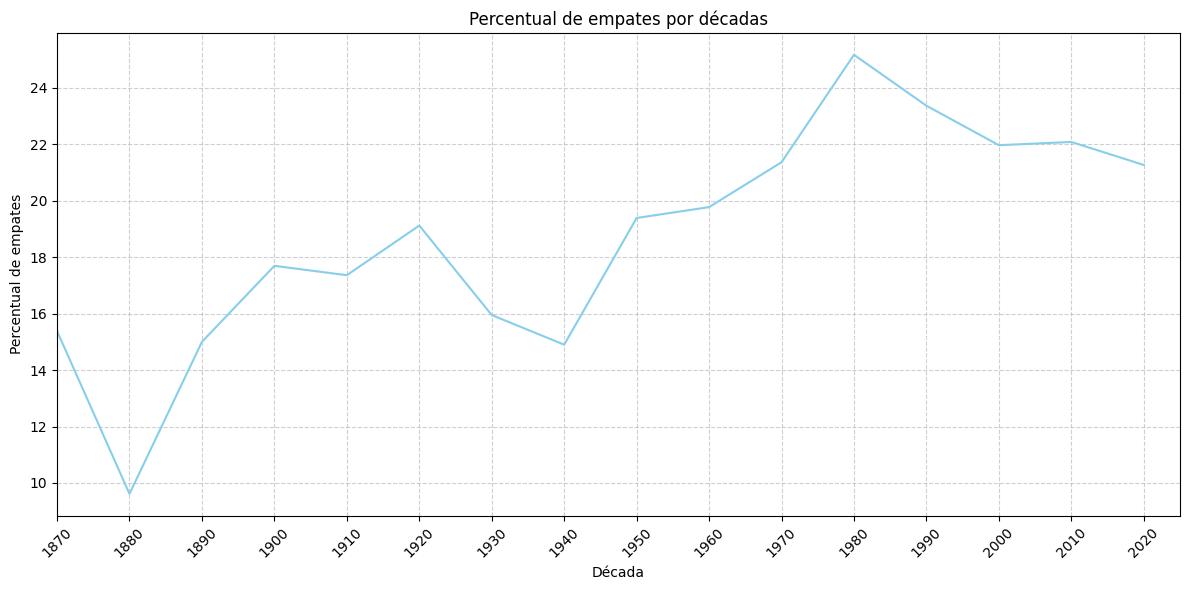

In [54]:
qtd_empates = df_partidas[e_empate].groupby((df_partidas['matchDate'].dt.year//10)*10).size()
qtd_jogos = df_partidas.groupby((df_partidas['matchDate'].dt.year//10)*10).size()
pct_empates = (qtd_empates/qtd_jogos) * 100

fig, ax = plt.subplots(figsize=(12, 6))
pct_empates.plot(kind='line', color='skyblue', linewidth=1.5, ax=ax)

ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_xlim(1870, 2025)
plt.xticks(rotation=45)

plt.title('Percentual de empates por décadas')
plt.xlabel('Década')
plt.ylabel('Percentual de empates')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

O gráfico apresenta a evolução do percentual de partidas terminadas empatadas por década. É possível observar que, apesar de algumas oscilações nas primeiras décadas, há uma **tendência geral de aumento da frequência de empates ao longo da história**. Equanto nas décadas iniciais os empates representavam aproximadamente **10% a 18%** das parttidas, esse percentual passa a superar **20%** a partir da década de 1970, atingindo seu maior valor na década de **1980**, com cerca de **25%** dos jogos terminando empatados.

Nas décadas mais recentes, o percentual de empates apresenta uma leve redução em relação ao pico observado nos anos 1980, estabilizando em torno de **21% a 22%**. Esse comportamento, em conjunto com a reduçõa da média de gols observada anteriormente, sugere um aumento do equilíbrio entre as seleções ao longo do tempo. Dessa forma, os resultados indicam que o futebol internaciona evoluiu para partidas masi disputadas e com menor diferença entre as equipes, tornando os empates relativamente mas frequentes do que nas primeiras décadas da série histórica.

## 5 - Todas as competições são iguais?

### 5.1 Média de gols por competições

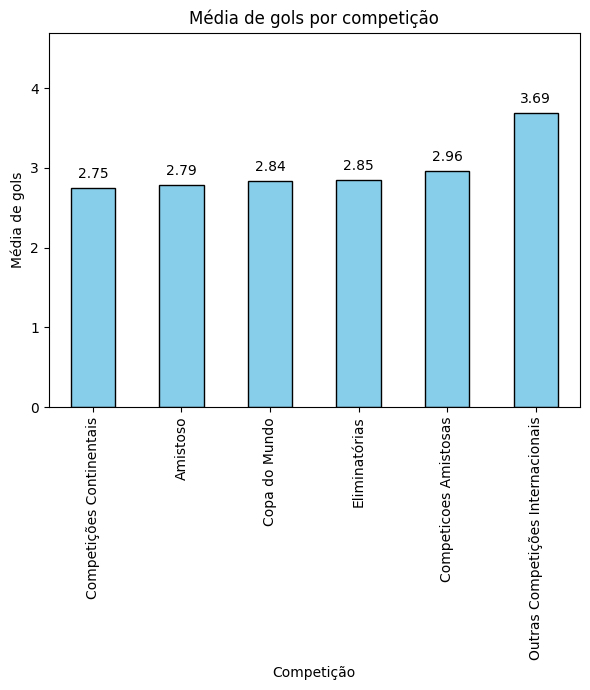

In [55]:
media_gols_por_competicao = df_partidas.groupby('competitionName')['totalGols'].mean().sort_values()

fig, ax = plt.subplots(figsize=(6, 7))

media_gols_por_competicao.plot(kind='bar', color='skyblue', edgecolor='black', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=5)
plt.title('Média de gols por competição')
plt.ylabel('Média de gols')
plt.xlabel('Competição')
plt.xticks(rotation=90)
plt.ylim(0, media_gols_por_competicao.max() + 1)
plt.tight_layout()
plt.show()

O gráfico evidencia que a **média de gols por partida é ralativamente semelhante entre a maioria das categorias de competição**, variando entre **2,75 e 2,96 gols por jogo**. As **competições amistosas** apresentam a maior média dentre as pricipais categoias (**2,96 gols**), enquanto as **competições continentais** registram a menor (**2,75 gols**). Já as eliminatórias e a Copa do Mundo apresentam médias muito próximas, de **2,85** e **2,84 gols**, respectivamente, indicando que o número médio de gols é relativamente estável independetemente do tipo de competição.

A principal exceção é a categoria **Outras Competições Internacionais**, cuja média é de **3,69 por partida**, valor significativamente superior às demais. Esse resultado pode estar relacionado ao memor número de partidas nessa categoria (**330 partidas**), tornando ela a menos representativa em relação ao conjunto de dados. De forma geral, o gráfico sugere que, apesar das diferenças no formato e na importância das competições, o número médio de gols por partida permanece próximo de **três gols**, indicando um comportamento consistente entre as diferentes categorias de torneios.

*A Copa do Mundo parece possuir mais gols que os amistosos.*

### 5.2 - Percentual de empates por competição

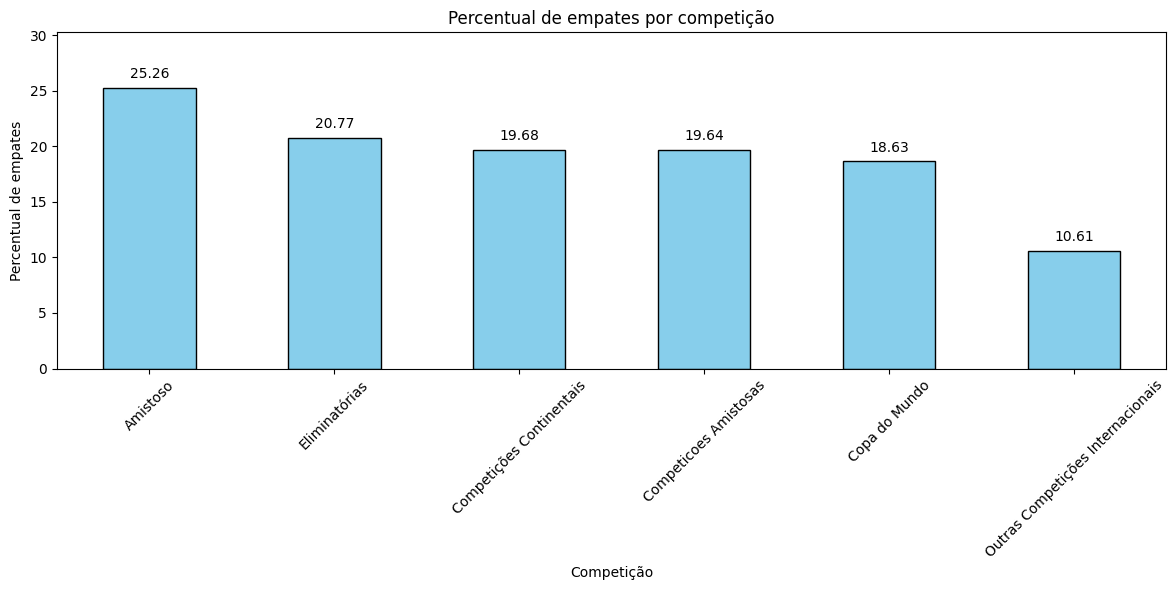

In [56]:
qtd_empates = df_partidas[e_empate].groupby('competitionName').size()
qtd_jogos = df_partidas.groupby('competitionName').size()
pct_empates = ((qtd_empates/qtd_jogos) * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
pct_empates.plot(kind='bar', color='skyblue', edgecolor='black', ax=ax)

ax.bar_label(ax.containers[0], fmt='%.2f', padding=5)
plt.title('Percentual de empates por competição')

plt.ylabel('Percentual de empates')
plt.xlabel('Competição')
plt.xticks(rotation=45)

plt.ylim(0, pct_empates.max() + 5)
plt.tight_layout()
plt.show()

## 6 - Quais são as chances de determinados resultados acontecerem?

### 6.1 - Qual a probabilidade de uma partida terminar empatada?

In [57]:
total_empates = len(df_partidas[e_empate])
total_partidas = len(df_partidas)
probalilidade_empate = (total_empates / total_partidas) * 100
print(f"Total de partidas que terminaram em empate: {total_empates}")
print(f"Total de partidas: {total_partidas}")
print(f"Probabilidade de uma partida terminar empatada: {probalilidade_empate:.2f}%")


Total de partidas que terminaram em empate: 10007
Total de partidas: 45831
Probabilidade de uma partida terminar empatada: 21.83%


Aproximadamente uma em cada cinco partidas termina empatada.

### 6.2 - Probabilidade de empate por competição?

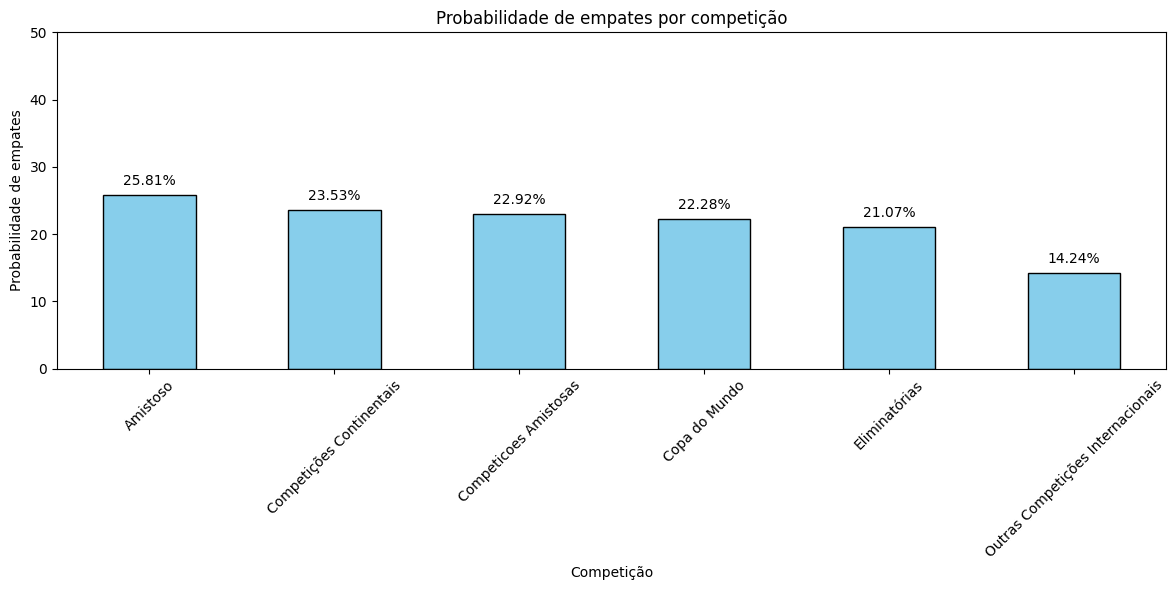

In [65]:
def calcula_propabilidade_empate(campeonato):
  e_campeonato = df_partidas['competitionName'] == campeonato
  e_empate_campeonato = (e_campeonato) & ((e_empate)|(df_partidas['teamAScore'] == df_partidas['teamBScore']))
  total_empate_campeonato = len(df_partidas[e_empate_campeonato])
  total_jogos_campeonato = len(df_partidas[e_campeonato])
  probabilidade_empate_campeonato = (total_empate_campeonato / total_jogos_campeonato) * 100
  return probabilidade_empate_campeonato


probabilidade_empates = pd.Series({campeonato.value: calcula_propabilidade_empate(campeonato.value) for campeonato in CampeonatosEnum}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 6))
probabilidade_empates.plot(kind='bar', color='skyblue', edgecolor='black', ax=ax)

ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=5)
plt.title('Probabilidade de empates por competição')

plt.ylabel('Probabilidade de empates')
plt.xlabel('Competição')
plt.xticks(rotation=45)

plt.ylim(0, 50)
plt.tight_layout()
plt.show()



### 6.3 - Qual a probabilidade de ocorrer 3 ou mais **gols**?

In [59]:
total_partidas_3_ou_mais_gols = len(df_partidas[df_partidas['totalGols'] >= 3])
probabilidade_3_ou_mais_gols = (total_partidas_3_ou_mais_gols / total_partidas) * 100

print(f"Total de partidas que tiveram mais de 3 gols: {total_partidas_3_ou_mais_gols}")
print(f"Probabilidade de uma partida terminar com mais de 3 gols: {probabilidade_3_ou_mais_gols:.2f}%")

Total de partidas que tiveram mais de 3 gols: 23421
Probabilidade de uma partida terminar com mais de 3 gols: 51.10%


A maioria das partidas, **51,1%**, apresenta três ou mais gols.

### 6.4 - Se uma partida teve mais de 4 gols, qual a chance dela não terminar empatada?

In [60]:
df_mais_4gols = df_partidas[df_partidas['totalGols'] > 4]
total_mais_4gols = len(df_mais_4gols)
e_empate_bola_rolando = (e_empate)|(df_mais_4gols['teamAScore'] == df_mais_4gols['teamBScore'])
df_vitorias_mais_4gols = df_mais_4gols[~e_empate_bola_rolando]
total_vitorias_mais_4gols = len(df_vitorias_mais_4gols)

probabilidade_vitoria = (total_vitorias_mais_4gols / total_mais_4gols) * 100

print(f"A probabilidade de uma partida com mais de 4 gols terminar em vitória é de: {probabilidade_vitoria:.2f}%")


A probabilidade de uma partida com mais de 4 gols terminar em vitória é de: 95.53%


## 7 - Quais afirmações podemos fazer sobre as partidas?

Para as análises, serão criadas amostras de 10% usando a técnica de amostragem estratificada. E o intervalo de confiaça será de 95%.

In [66]:
def cria_amostra(campeonato):
  df_amostra = df_partidas.loc[df_partidas.competitionName == campeonato].sample(frac=0.10)
  return df_amostra

df_amostra_por_campeonatos = pd.concat(
    [cria_amostra(campeonato.value) for campeonato in CampeonatosEnum]
)

total_gols = df_amostra_por_campeonatos['totalGols'].sum()
print("Dados amostral")
print(f"Média: {df_amostra_por_campeonatos['totalGols'].mean():.2f}")
print(f"Mediana: {df_amostra_por_campeonatos['totalGols'].median():.2f}")
print(f"Desvio padrão: {df_amostra_por_campeonatos['totalGols'].std():.2f}")

Dados amostral
Média: 2.84
Mediana: 3.00
Desvio padrão: 1.99


### 7.1 A média de gols em amistosos é diferente da média de gols das partidas oficias?

* **H0** - A média de gols em Amistosos é igual à média das demais partidas.
* **H1** - A média de gols em Amistosos é diferente à média das demais partidas.

In [62]:
media_amostral = df_amostra_por_campeonatos['totalGols'].mean()
desvio_padrao_amostral = df_amostra_por_campeonatos['totalGols'].std()
erro_padrao = desvio_padrao_amostral/sqrt(len(df_amostra_por_campeonatos))
margem_erro = 1.96*erro_padrao
valor_critico = norm.ppf(0.975)
intervalo_confianca = (media_amostral - valor_critico * erro_padrao,
                       media_amostral + valor_critico * erro_padrao)

print(f"Média: {media_amostral:.2f}")
print(f"Desvio padrão: {desvio_padrao_amostral:.2f}")
print(f"Erro padrão: {erro_padrao:.2f}")
print(f"Margem de erro: {margem_erro:.2f}")
print(f"Intervalo de confiança de 95%: {intervalo_confianca}")

gols_amistosos = df_amostra_por_campeonatos[df_amostra_por_campeonatos['competitionName'] == CampeonatosEnum.AMISTOSO.value]['totalGols']
gols_nao_amistosos = df_amostra_por_campeonatos[df_amostra_por_campeonatos['competitionName'] != CampeonatosEnum.AMISTOSO.value]['totalGols']
_,p_amistosos = shapiro(gols_amistosos)
_,p_nao_amistosos = shapiro(gols_nao_amistosos)

print(f"Valor de P dos amistosos: {p_amistosos}")
print(f"Valor de P das demais partidas: {p_nao_amistosos}")



Média: 2.86
Desvio padrão: 1.98
Erro padrão: 0.03
Margem de erro: 0.06
Intervalo de confiança de 95%: (np.float64(2.805580528975957), np.float64(2.920422961425439))
Valor de P dos amistosos: 3.4431926343450235e-28
Valor de P das demais partidas: 2.3912415039319104e-39


Como o valor de P foi **menor** que 0,05, os dados referente aos gols das partidas não segue uma distribuição normal. Dessa forma, para o teste da hipótese, será utilizado um teste não paramêtrico. Sendo um teste não paramétrico, e também duas amostras independentes, o teste utilizado é Mann-Whitney

In [63]:
_,p = mannwhitneyu(gols_amistosos, gols_nao_amistosos)
print(f"Valor de p: {p}")

Valor de p: 0.14131600285175402


Há evidências estatísticas de que a média do número de gols em partidas amistosas é igual as demais partidas.

### 7.2 - Há relação entre o tipo de resultado das partidas e o campeonato?

* **H0** - O  Resultado da partida é independente do campeonato disputado.
* **H1** - Existe associação entre o campeonato disputado e o resultado da partida.

In [71]:
tabela = pd.crosstab(
    df_amostra_por_campeonatos["competitionName"],
    df_amostra_por_campeonatos["resultType"]
)

resultado = chi2_contingency(tabela)

print(f"p-valor: {resultado.pvalue}")

p-valor: 3.266397608659717e-43


Há evidências estatísticas de que o tipo de resultado (Tempo normal, prorrogação e decisão por pênaltis) está associado ao campeonato em disputa.

## 8 - Considerações

Ao iniciar este trabaho, a principal pergunta era se seria possível compreender a história do futebol entre seleções apenas por meio dos dados. Ao longo da análise, cada etapa revelou uma parte dessa história. Conhecemos a estrutura do conjunto de dados, identificamos como normalmente são as partidas, observamos a evolução do futebol ao longo das décadas e verificamos que diferentes competições apresentam caracteristicas próprias. Assim, os dados mostram que, por trás de milhares de jogos disputados ao longo de quase 150 anos, existem padrões que podem ser descritos e interpretados por meio da estatístiva.

Mais do que descrever os dados, este trabalho demonstrou como a probabilidade e a inferência estatística permitem transformar observações em conhecimento. As estimativas probabilísticas quantificaram eventos comuns do futebol, enquanto os testes estatísticos possibilitaram verificar se diferenças observadas entre competições eran realmente significativas, evidenciando a importância dessas ferramentas na análise de fennômenos reais.

O futebol serviu como objeto de estudo, mostrando que um conjunto de dados histórico pode revelar tendências, confirmar hipóteses e oferecer uma compreensão mais profunda da evolução do esporte ao longo do tempo.